In [1]:
# imports
import simpy
import numpy as np
import sys
import pandas as pd
import os
from IPython.display import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import time
sys.path.append('../code/pycharm')
from single_station_transient import *
from utils import *
import pickle as pkl

## Transient analysis: form queue lenght to waiting time

<div dir="rtl">

## בתרגול זה ננסה להבין כיצד למדוד את הworkload של המערכת

### נניח כי יש לנו מערכת עם קצב הגעה לפי:

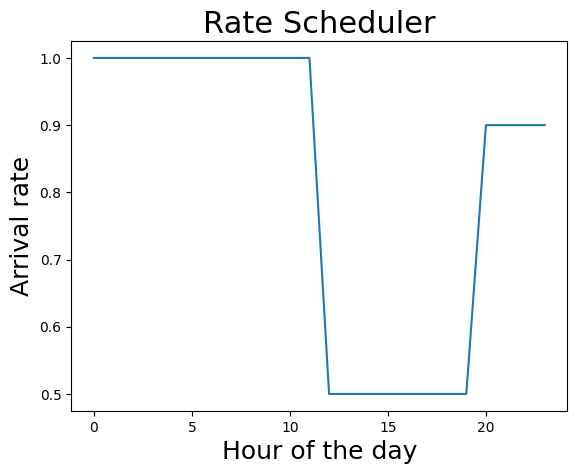

In [2]:
dict_sch = {0:1, 12:0.5,20:0.9}

arrival_scd_pd = convert_dict_to_pd(dict_sch)
arrival_scd_pd

rates = []
for hour in range(24):
    rates.append(give_rate_per_time(arrival_scd_pd,  hour))

plt.figure()
plt.plot(np.arange(24), rates)
plt.xlabel('Hour of the day', fontsize = 18)
plt.ylabel('Arrival rate', fontsize = 18)
plt.title('Rate Scheduler', fontsize = 22)
plt.show()

<div dir="rtl">


## במה הסימולציה שונה מהותית מהמקרה שבו חישבנו רק את התפלגות אורך התור?

### אם נרצה לחשב את הworkload בכל נקודה נצטרך לדעת את זמני השירות של הצרכנים שעדיין בתור.

### בד"כ אנחנו מגרילים זמני שירות רק כשצרכן נכנס לשירות. 

### לכן, נצטרך לעשות פה משהו שונה  - במקום נגריל זמני שירות של כל צרכן בהגעה. 

### נשתמש במידע הזה ברגע שהצרכן נכנס לשירות. 

### נראה בקוד כיצד זה נראה, כל שינוי בקוד מסומן ב@@@@@@@@@@

In [3]:
class Queue_single_station_waiting_time:

    def __init__(self, arrival_scd_pd, mu, sim_time):

        self.env = simpy.Environment() # initializing simpy enviroment 
        self.server = simpy.Resource(self.env, capacity=1) # Defining a resource with capacity 1
        self.end_time = sim_time # The time simulation terminate
        self.id_current = 1 # keeping track of cusotmers id
        self.df_events = pd.DataFrame([]) # is a dataframe the holds all information of the queue dynamic:
        #an event can one of three: (1. arrival, 2. entering service 3. service completion)
        
        self.df_waiting_times = pd.DataFrame([]) # is a dataframe the holds all information waiting time
        self.mu = mu # service rate
        self.num_cust_sys = 0 # keeping track of number of customers in the system
        
        ## @@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
        self.service_times = {}
        ## @@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
        
        self.event_log_customer_id_list = []
        self.event_log_num_cust_list = []
        self.event_log_type_list = []
        self.event_log_time_stamp = []
        
        self.arrival_pd = arrival_scd_pd

    def run(self):

        self.env.process(self.customer_arrivals()) ## Initializing a process
        self.env.run(until=self.end_time) ## Running the simulaiton until self.end_time

   
    
    def give_rate_per_time(self, time):
        
        ind_rate = self.arrival_pd.loc[self.arrival_pd['LB_time']<=time, :].index[-1]
        return self.arrival_pd.loc[ind_rate, 'arrival_rate']
        
    
    #########################################################
    ################# Service block ######################### 
    ######################################################### 
    
    
    def service(self, customer):

        with self.server.request() as req:
                       

            yield req

            self.event_log_customer_id_list.append(customer.id) 
            self.event_log_time_stamp.append(self.env.now)     
            self.event_log_num_cust_list.append(self.num_cust_sys)
            
            ## @@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
            self.event_log_type_list.append('Start service')
            ## @@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@

            ## @@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
            yield self.env.timeout(customer.service_time)
            ## @@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@


            #we compute how much time the system had this number of customers
            
            self.num_cust_sys -= 1 # updating number of cusotmers in the system
 
            self.event_log_customer_id_list.append(customer.id)
            self.event_log_time_stamp.append(self.env.now)
            self.event_log_num_cust_list.append(self.num_cust_sys)
            self.event_log_type_list.append('Departure')
                       

           

    #########################################################
    ################# Arrival block ######################### 
    ######################################################### 
    
    
    def customer_arrivals(self):

        while True:

            arrival_rate = self.give_rate_per_time(self.env.now) 
            
            yield self.env.timeout(np.random.exponential(1/arrival_rate))


            
            curr_id = self.id_current
            arrival_time = self.env.now
            ## @@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
            service_time = np.random.exponential(1/self.mu)
            customer = Customer(curr_id, arrival_time, 1, service_time)
            self.service_times[curr_id] = service_time
            ## @@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
            self.event_log_customer_id_list.append(customer.id) 
            self.event_log_time_stamp.append(self.env.now)
            
      
            
            self.num_cust_sys += 1
            self.event_log_num_cust_list.append(self.num_cust_sys)
            self.event_log_type_list.append('Arrival')

            self.id_current += 1



            self.env.process(self.service(customer))

class Customer:
    def __init__(self, id, arrival_time, station, service_time):
        self.id = id
        self.arrival_time = arrival_time
        self.station = station
        ## @@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
        self.service_time = service_time
        ## @@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@

In [4]:
lamda = 1
mu  = 1
sim_time = 20


sim_time +=1
sim_instance = Queue_single_station_waiting_time(arrival_scd_pd, mu, sim_time)
sim_instance.run()

In [5]:
event_log = pd.DataFrame({'Customer_id': sim_instance.event_log_customer_id_list,
                                  'Time_stamp': sim_instance.event_log_time_stamp,
                                  'Type': sim_instance.event_log_type_list,
                                  'num_cust': sim_instance.event_log_num_cust_list})

In [6]:
event_log.head()

,Customer_id,Time_stamp,Type,num_cust
0,1,0.204121,Arrival,1
1,1,0.204121,Start service,1
2,1,0.247894,Departure,0
3,2,1.200522,Arrival,1
4,2,1.200522,Start service,1


<div dir="rtl">

### יש לנו כרגע יומן ארועים שאותו צריך להמיר לworkload ברגעי שנקבעו מראש

### במקרה שלנו זה כל דקה עגולה

### הפונקציה workload לוקחת את יומן הארועים וומירה את זה לworkload

### לא ניכנס לפרטים בפונקציה הזאת  - זה עניין טכני שנוותר עליו. 

In [7]:
def get_workload(sim_instance, time_points=range(1, 21)):

    df = pd.DataFrame({
        'Customer_id': sim_instance.event_log_customer_id_list,
        'Time_stamp': sim_instance.event_log_time_stamp,
        'Type': sim_instance.event_log_type_list,
        'num_cust': sim_instance.event_log_num_cust_list
    })

    arrivals = (
        df[df["Type"] == "Arrival"]
        .set_index("Customer_id")["Time_stamp"]
        .to_dict()
    )

    starts = (
        df[df["Type"] == "Start service"]
        .set_index("Customer_id")["Time_stamp"]
        .to_dict()
    )

    service_times = sim_instance.service_times

    workload = {}

    for t in time_points:

        W = 0.0

        for customer, arrival in arrivals.items():

            if arrival > t:
                continue

            s = service_times[customer]

            if customer not in starts or starts[customer] > t:
                # Customer is waiting at time t
                W += s

            else:
                # Customer has started service
                elapsed = t - starts[customer]

                # If service hasn't finished, add residual
                W += max(s - elapsed, 0.0)

        workload[t] = W

    return workload

get_workload(sim_instance)

{1: 0.0,
 2: 0.0,
 3: 0.395340342749422,
 4: 2.396622157761103,
 5: 5.320128113052929,
 6: 9.94209729302689,
 7: 8.94209729302689,
 8: 8.856093440648793,
 9: 7.8560934406487934,
 10: 7.940201781203461,
 11: 8.383608072927782,
 12: 7.383608072927783,
 13: 7.713312414827535,
 14: 6.713312414827535,
 15: 6.130420741005768,
 16: 5.130420741005768,
 17: 4.13042074100577,
 18: 3.1304207410057696,
 19: 4.431750052127882,
 20: 3.43175005212788}

<div dir="rtl">

### בסוף קיבלנו מילון שנותן את הworkload עבור כל דקה עגולה

### נעטוף את הכל בפונקציה בודדת: 

In [8]:
def give_workload_per_sim(lamda, mu, sim_time):
    
    sim_instance = Queue_single_station_waiting_time(arrival_scd_pd, mu, sim_time)
    sim_instance.run()

    return get_workload(sim_instance)

<div dir="rtl">


### נריץ 50000 פעמים ואז נוכל לדעת התפלגות workload כפונקציה של הזמן

In [9]:
list_of_sims = []
for ind in tqdm(range(50000)):

    list_of_sims.append(give_workload_per_sim(lamda, mu, sim_time))
    

100%|████████████████████████████████████████████████████████████████████████████████| 50000/50000 [10:36<00:00, 78.59it/s]


In [ ]:
list_of_sims[4]

In [ ]:
sim_time

In [10]:
time_dict = {}

for time in range(1, sim_time):
    time_dict[time] = []

for time in tqdm(range(1, sim_time )):
    for sim in list_of_sims:
        time_dict[time].append(sim[time]) 

100%|██████████████████████████████████████████████████████████████████████████████████████| 20/20 [00:00<00:00, 34.77it/s]


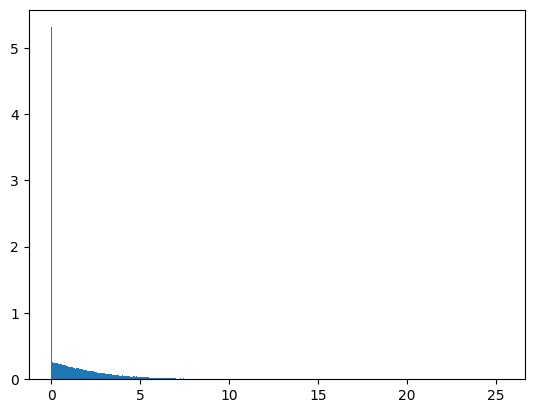

In [11]:
plt.figure()
plt.hist(time_dict[3], density = True, bins = 400)
plt.show()

In [12]:
mean_values = []

for time in range(1, 21):
    mean_values.append(np.array(time_dict[time]).mean())


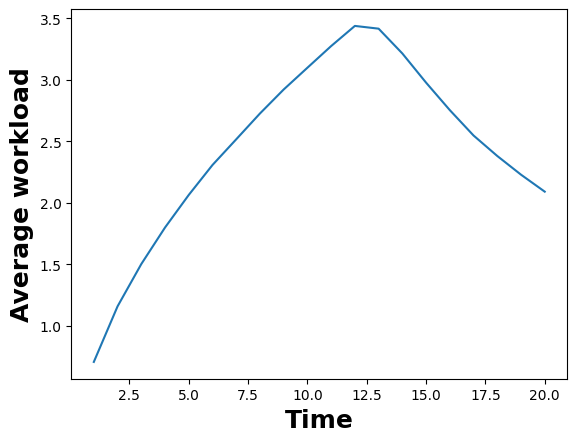

In [15]:
plt.figure()
plt.plot(np.arange(1,21), mean_values)
plt.xlabel('Time', fontsize = 18, fontweight = 'bold')
plt.ylabel('Average workload', fontsize = 18, fontweight = 'bold')
plt.show()


<div dir="rtl">

### החישוב למעלה הוא תוחלת הworkload כפונקציה של הזמן. 

### איזה עוד מדדים נרצה לחשב?

### 1. הסתברות שהworkload יהיה קטן, גדול או בין שני ערכים.

### למשל: P(workload > 2), P(workload < 3), P(2 < workload < 3)?

### 2. שונות של הworkload

### אז איך נחשב?

In [27]:
## workload at t = 3
time_3_workload = np.array(time_dict[3])

<div dir="rtl">

## כדי לחשב הסתברות נרצה לדעת מה פרופורציות המקרים שהworkload היה בתחום המבוקש. 

### למשל:

In [29]:
# P(workload <3)?
(time_3_workload < 3).mean()

np.float64(0.8205)

In [30]:
# P(workload > 2)?

(time_3_workload > 2).mean()

np.float64(0.2897)

In [31]:
# P(2 < workload < 3)?

((time_3_workload > 2) & (time_3_workload < 3 )).mean()

np.float64(0.1102)

<div dir="rtl">

## מה לגבי שונות?


In [34]:
# V(workload)

time_3_workload.std()**2 ## std - זה סטיית תקן

np.float64(3.7689860354305513)

<div dir="rtl">

### כמובן שסטיית התקן היא:

In [33]:
time_3_workload.std()

np.float64(1.9413876571747724)

<div dir="rtl">

## נחשב את המדדים כפונקציה של הזמן. עד עכשיו זה הכל היה עבור t = 3 בלבד.


In [36]:
prob_2_3 = []

for time in range(1, 21):
    curr_arr   = np.array(time_dict[time])
    prob_2_3.append( ((curr_arr>2) & (curr_arr < 3)).mean())



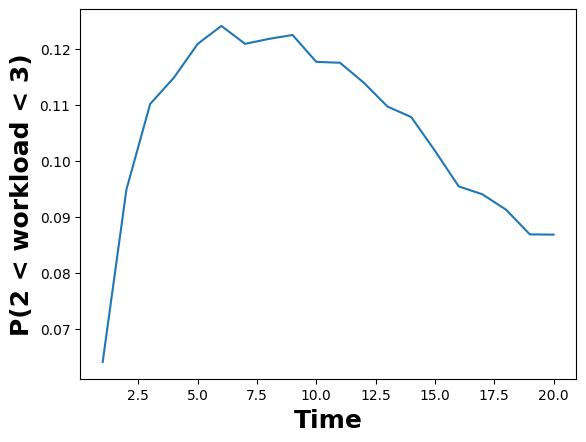

In [38]:


plt.figure()
plt.plot(np.arange(1,21), prob_2_3)
plt.xlabel('Time', fontsize = 18, fontweight = 'bold')
plt.ylabel('P(2 < workload < 3)', fontsize = 18, fontweight = 'bold')
plt.show()

In [41]:
std = []

for time in range(1, 21):
    curr_arr   = np.array(time_dict[time])
    std.append( curr_arr.std())

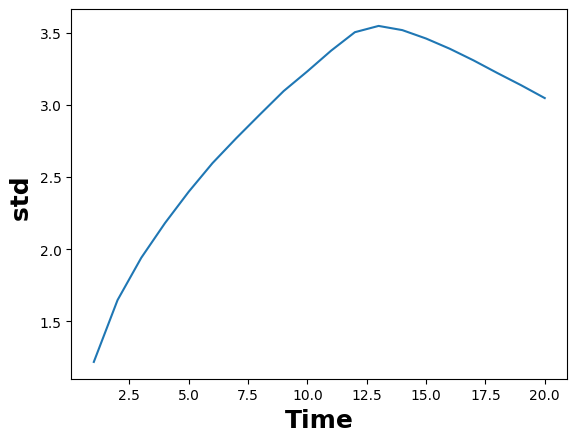

In [42]:
plt.figure()
plt.plot(np.arange(1,21), std)
plt.xlabel('Time', fontsize = 18, fontweight = 'bold')
plt.ylabel('std ', fontsize = 18, fontweight = 'bold')
plt.show()